# How Does ChatGPT Pick the Next Word?
### Sets, dictionaries, and a tiny language model

A large language model (LLM) like ChatGPT writes **one word at a time**. Each time, it gives every word it knows a
probability, then picks one.

In this notebook you'll build a tiny version of that with **sets** and **dictionaries**:

1. **Describe** two functions as if you were prompting ChatGPT, then compare with a neighbor. They find the model's
   **vocabulary** (a set) and **count** how often each word appears (a dict).
2. Record **which words come after each word**.
3. Use that to **write new sentences**, one random pick at a time.

Run each cell in order with **Shift + Enter**. Cells marked ✏️ are for you to write code in.

## Setup
Run this cell. It imports `random` and defines `bar_chart`, a helper that draws a dict as a bar chart.
You don't need to read the helper's code.

In [1]:
import random
import matplotlib.pyplot as plt


def bar_chart(data: dict[str, int], title: str) -> None:
    """Draw a bar chart of a dict, tallest bar first. (You don't need to read this.)"""
    labels: list[str] = []
    for key in data:
        labels.append(key)
    labels.sort(key=data.get, reverse=True)
    heights: list[int] = []
    for label in labels:
        heights.append(data[label])
    plt.figure(figsize=(7, 3))
    plt.bar(labels, heights, color="#9B8DE0")
    plt.title(title)
    plt.show()


print("Setup done!")

Setup done!


## Part 1: Our training text
ChatGPT learned from trillions of words. We'll learn from 17:

> the cat sat on the mat
> the dog sat on the rug
> the cat ate the fish

We glue the three sentences into one list of words.

In [2]:
words: list[str] = ["the", "cat", "sat", "on", "the", "mat",
                    "the", "dog", "sat", "on", "the", "rug",
                    "the", "cat", "ate", "the", "fish"]
print(len(words))

17


## ✏️ Describe the code as if you were prompting ChatGPT
Our language model needs two tools: one that finds its **vocabulary** (the set of every word it can write) and one
that **counts** how often each word appears. Both are written for you below.

Being able to read code and say **what it does** is a key skill, and it's exactly what you need to write a good
prompt for an AI tool. For each function:

1. **Read** the code and run the cell.
2. **Write the prompt** you would give ChatGPT so that it writes this function for you. Use 1 or 2 sentences.
   Describe **what** the function does (its purpose), not **how** it does it line by line.
   Say what goes in and exactly what comes out.

Then **compare** your two prompts with a neighbor.

### `vocabulary`
Real LLMs have a vocabulary too: roughly 100,000 or more words and word pieces (called **tokens**).

In [3]:
def vocabulary(words: list[str]) -> set[str]:
    vocab: set[str] = set()
    for word in words:
        vocab.add(word)
    return vocab


print(vocabulary(["hi", "bye", "hi"]))

{'hi', 'bye'}


**✏️ My prompt for `vocabulary`:** *(double-click this cell and replace this text with your prompt)*

### `count_words`

In [4]:
def count_words(words: list[str]) -> dict[str, int]:
    counts: dict[str, int] = {}
    for word in words:
        if word in counts:
            counts[word] += 1
        else:
            counts[word] = 1
    return counts


print(count_words(["hi", "bye", "hi"]))

{'hi': 2, 'bye': 1}


**✏️ My prompt for `count_words`:** *(double-click this cell and replace this text with your prompt)*

### 👥 Compare with a neighbor
Read each other's prompts and talk through these questions:

- Did you both say what goes **in** and exactly what comes **out** (a set? a dict? a number?)?
- For `count_words`, did you say what the **keys** and **values** of the dictionary are?
- Did either of you describe the code **line by line** instead of describing its purpose?
- If ChatGPT only saw your prompt, would it write a function that **behaves the same**? Why or why not?
- Whose prompt was clearer? What would you change in yours now?

**✏️ What I'd change after comparing:** *(double-click to answer)*

### Using our two tools
Run this cell to find the vocabulary and word counts of our training text.
The rest of the notebook uses `vocab` and `counts`.

{'mat', 'rug', 'dog', 'fish', 'sat', 'ate', 'cat', 'the', 'on'}
{'the': 6, 'cat': 2, 'sat': 2, 'on': 2, 'mat': 1, 'dog': 1, 'rug': 1, 'ate': 1, 'fish': 1}


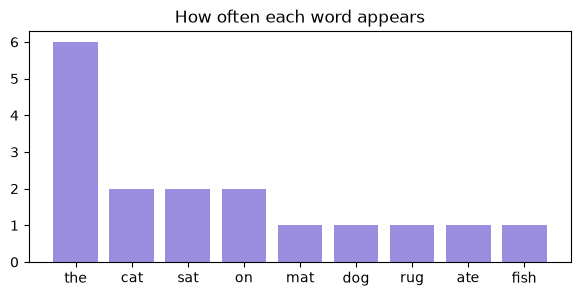

In [5]:
vocab: set[str] = vocabulary(words)
counts: dict[str, int] = count_words(words)
print(vocab)
print(counts)
bar_chart(counts, "How often each word appears")

**Predict, then check:** `words` has 17 items. How many does `vocab` have? How many keys does `counts` have? Why?

In [6]:
print(len(words), len(vocab), len(counts))

17 9 9


### Counting alone isn't enough
If our model always picked the most common word, it would write *"the the the the the..."*.
To pick a sensible next word, we need to know which words came **after the current word**.

Look at the training text again. After `"the"`, the next word was `cat`, `mat`, `dog`, `rug`, `cat`, `fish`.

## ✏️ Practice 1 (dict of lists): what comes next?
Write `build_follows` so it returns a dict where:
* each **key** is a word, and
* each **value** is the **list** of words that came right after it, in order, **repeats included**.

For example, `follows["sat"]` should be `["on", "on"]`.

Tips:
* Loop over each position `i` except the last one, so `words[i + 1]` always exists.
* If `words[i]` isn't a key yet, give it an empty list first. Then `append` the next word.

<details>
<summary>Stuck? Click for the fill-in-the-blanks version.</summary>

```python
def build_follows(words: list[str]) -> dict[str, list[str]]:
    follows: dict[str, list[str]] = {}
    for i in range(len(words) - ____):
        word: str = words[i]
        next_word: str = words[____]
        if word not in follows:
            follows[word] = ____
        follows[word].append(____)
    return follows
```
</details>

In [ ]:
def build_follows(words: list[str]) -> dict[str, list[str]]:
    """Return a dict mapping each word to the list of words that came right after it."""
    follows: dict[str, list[str]] = {}
    # TODO
    return follows

In [ ]:
follows: dict[str, list[str]] = build_follows(words)
for word in follows:
    print(word, "->", follows[word])

assert follows.get("the") == ["cat", "mat", "dog", "rug", "cat", "fish"], f'follows["the"] is {follows.get("the")}'
assert follows.get("sat") == ["on", "on"], f'follows["sat"] is {follows.get("sat")}'
assert follows.get("on") == ["the", "the"], f'follows["on"] is {follows.get("on")}'
assert "fish" not in follows, '"fish" should not be a key: nothing came after it'
assert build_follows(["hi"]) == {}, "One word has nothing after it, so the dict should be empty"
print("All Practice 1 tests passed!")

**Predict, then run:** what do these print?

In [ ]:
print(len(follows["the"]))
print(len(set(follows["the"])))

The **list** remembers *how often* each word came next. The **set** only tells us *which* words are possible.

## A list with repeats is a weighted die
`random.choice(follows["the"])` picks one of the 6 items, each equally likely.
Since `"cat"` is in the list twice, it comes up **2 out of 6** times, about 33%.

Let's check by rolling 600 times and counting the results with `count_words`.
About how many times should `"cat"` come up?

In [ ]:
rolls: list[str] = []
for i in range(600):
    rolls.append(random.choice(follows["the"]))

roll_counts: dict[str, int] = count_words(rolls)
print(roll_counts)
bar_chart(roll_counts, 'Picking the word after "the", 600 times')

Run that cell a few times. The numbers change a little each time, but `"cat"` is always about twice as common
as the others. That's how an LLM writes: **probabilities for the next word, then a random pick.**

## ✏️ Practice 2 (dicts): from counts to probabilities
At the start of class we saw that an LLM gives every possible next word a **probability**. Now you'll compute
real probabilities from our training text.

`next_word_probabilities(follows, word)` answers the question: **"After `word`, how likely is each next word?"**
It returns a dict where each **key** is a word that came after `word`, and each **value** is the fraction of the
time it came next (a `float` between 0 and 1).

**Worked example** for `"the"`:

| | |
|---|---|
| `follows["the"]` | `["cat", "mat", "dog", "rug", "cat", "fish"]`: 6 words in total |
| `"cat"` appears 2 times | `2 / 6` ≈ `0.33` |
| `"mat"`, `"dog"`, `"rug"`, `"fish"` each appear 1 time | `1 / 6` ≈ `0.17` |

So `next_word_probabilities(follows, "the")` returns
`{"cat": 0.333..., "mat": 0.166..., "dog": 0.166..., "rug": 0.166..., "fish": 0.166...}`.

**Steps:**
1. Get the list of words that came after `word`: `follows[word]`.
2. Count them with `count_words`. (You already have it!)
3. Make an empty dict. For each key in the counts, store its count **divided by** the length of the list.

In [ ]:
def next_word_probabilities(follows: dict[str, list[str]], word: str) -> dict[str, float]:
    """Return a dict mapping each word that came right after word
    to the fraction of the time it came next."""
    probs: dict[str, float] = {}
    # TODO
    return probs

In [ ]:
probs: dict[str, float] = next_word_probabilities(follows, "the")
for word in probs:
    print(word, round(probs[word], 2))

assert abs(probs.get("cat", 0) - 2 / 6) < 0.001, f'Expected about 0.33 for "cat" but got {probs.get("cat")}'
assert abs(probs.get("fish", 0) - 1 / 6) < 0.001, f'Expected about 0.17 for "fish" but got {probs.get("fish")}'
assert next_word_probabilities(follows, "on") == {"the": 1.0}, 'After "on", "the" should have probability 1.0'
print("All Practice 2 tests passed!")

## Writing a sentence
`generate` is given to you. It writes one word at a time:
look up the current word, roll the weighted die with `random.choice`, and add the result.
It stops after `n` words, or early at a word with no key (like `"fish"`).

Run the next cell several times. Do you ever get a sentence that **isn't** in the training text?

In [ ]:
def generate(follows: dict[str, list[str]], start: str, n: int) -> str:
    """Write up to n words, starting with start."""
    sentence: str = start
    word: str = start
    count: int = 1
    while count < n and word in follows:
        word = random.choice(follows[word])
        sentence += " " + word
        count += 1
    return sentence


for i in range(5):
    print(generate(follows, "the", 6))

## Try it yourself: more training text
Add your own sentences to `my_words`, rebuild `follows`, and generate. What happens as the training text grows?

In [ ]:
my_words: list[str] = ["the", "cat", "sat", "on", "the", "mat",
                       "the", "dog", "sat", "on", "the", "rug",
                       "the", "cat", "ate", "the", "fish",
                       "the", "dog", "ate", "the", "bone"]  # add more words here!

my_follows: dict[str, list[str]] = build_follows(my_words)
print("Vocabulary:", vocabulary(my_words))
for i in range(5):
    print(generate(my_follows, "the", 8))

## From our toy model to ChatGPT

| | Our tiny model | ChatGPT-style LLM |
|---|---|---|
| Training text | 3 short sentences | Trillions of words from books, websites and code |
| Vocabulary | A **set** of 9 words | Roughly 100,000+ tokens |
| Looks back at | Just 1 word | Thousands of earlier words |
| Next-word chances come from | Counting, in a **dict of lists** | A neural network trained to predict the next word |
| Picks the next word by | `random.choice` | Sampling from the probabilities: same idea! |

**Why context matters:** after `"the"`, our model can't tell *"the cat ate the ___"* from *"the dog sat on the ___"*.
An LLM uses every earlier word to set its probabilities.

### Recap
* A **set** of every word it knows is the model's **vocabulary**.
* A **dictionary** stores what we learned from the training text: word counts, or the list of words that came after each word.
* A list with repeats is a **weighted die**. Random picks are why the same prompt can give different answers.

## 🏠 Take-home challenge (optional): could our model write this?
Our model builds a sentence one pair of words at a time, so it can only write a sentence if **every pair of
neighboring words** appeared somewhere in the training text.

`can_generate(follows, sentence)` takes a sentence as a **list of words** and returns `True` if our model could
write it, or `False` if it never could.

**Worked example:** `["the", "dog", "ate"]`

| Pair | Check | OK? |
|---|---|---|
| `"the"` → `"dog"` | Is `"dog"` in `follows["the"]`? Yes | ✅ |
| `"dog"` → `"ate"` | Is `"ate"` in `follows["dog"]`? No, `follows["dog"]` is `["sat"]` | ❌ |

One pair fails, so the answer is `False`.

**Steps:**
1. Loop over each position `i` except the last one (just like `build_follows`).
2. If `sentence[i]` is **not** a key in `follows`, return `False`. (Nothing ever came after that word.)
3. If `sentence[i + 1]` is **not** in `follows[sentence[i]]`, return `False`.
4. If the loop finishes without returning, every pair passed: return `True`.

In [ ]:
def can_generate(follows: dict[str, list[str]], sentence: list[str]) -> bool:
    """Return True if every pair of neighboring words in sentence
    appeared in the training text (so our model could write it)."""
    # TODO
    return False

In [ ]:
print(can_generate(follows, ["the", "cat", "sat", "on", "the", "rug"]))
print(can_generate(follows, ["the", "dog", "ate", "the", "fish"]))

assert can_generate(follows, ["the", "cat", "sat", "on", "the", "rug"]) == True, "This one should be possible"
assert can_generate(follows, ["the", "dog", "ate", "the", "fish"]) == False, '"dog" is never followed by "ate"'
assert can_generate(follows, ["the", "mat", "the", "cat", "ate", "the", "fish"]) == True, "This one is silly but possible"
assert can_generate(follows, ["the", "fish", "sat"]) == False, '"fish" has no key, so nothing can follow it'
print("All take-home challenge tests passed!")